# HOT Cloud Detection - Belize Patch v1

**Quick demonstration of HOT cloud detection on Belize-Wildfires-June24 scenes.**

This is a minimal v1 implementation while waiting for the full scene list and tiling infrastructure.

**Scenes:**
- 61% cloud: 16/033131012101/1040010051B60600
- 18% cloud: 16/033131012120/104001008884A400
- 6% cloud: 16/033131012122/104001008884A400

## 1. Setup

In [62]:
!pip install -q rasterio numpy matplotlib scikit-learn pandas pystac leafmap

import numpy as np
import matplotlib.pyplot as plt
import rasterio
from rasterio.windows import Window
import pystac
import warnings
warnings.filterwarnings('ignore')

print("Libraries imported!")

Libraries imported!


## 2. Load Belize Scenes from Maxar Open Data

In [63]:
# Connect to Maxar Open Data catalog
CATALOG_URL = "https://maxar-opendata.s3.amazonaws.com/events/catalog.json"
catalog = pystac.Catalog.from_file(CATALOG_URL)

# Get Belize-Wildfires-June24 event
belize_event = catalog.get_child('Belize-Wildfires-June24')
print(f"Event: {belize_event.id}")

# Sample items with cloud cover metadata
items = list(belize_event.get_items(recursive=True))
print(f"Total items in event: {len(items)}")

# Filter for items with cloud cover info
with_cc = []
for item in items:
    cc = item.properties.get("tile:clouds_percent",
                             item.properties.get("eo:cloud_cover"))
    if cc is not None:
        with_cc.append({
            'id': item.id,
            'cloud_cover': cc,
            'item': item
        })

# Sort by cloud cover
with_cc.sort(key=lambda x: x['cloud_cover'], reverse=True)
print(f"\nItems with cloud cover: {len(with_cc)}")
print("\nTop 5 cloudiest scenes:")
for i, item in enumerate(with_cc[:5]):
    print(f"  {i+1}. [{item['cloud_cover']:.0f}% cloud] {item['id']}")

Event: Belize-Wildfires-June24
Total items in event: 90

Items with cloud cover: 90

Top 5 cloudiest scenes:
  1. [71% cloud] 16/033131012011/105001003B701E00
  2. [70% cloud] 16/033131012132/105001003B701E00
  3. [67% cloud] 16/033131012111/105001003B701E00
  4. [67% cloud] 16/033131012131/105001003B701E00
  5. [64% cloud] 16/033131012113/105001003B701E00


## 3. Define HOT Detection Function

In [64]:
def detect_hot(image, threshold=0.05, blue_slope=1.0, blue_intercept=0.0):
    """
    Cloud detection using HOT (Hazed Optimized Transformation) index.

    Parameters:
    -----------
    image : numpy array
        RGB image with shape (height, width, 3) or (3, height, width)
    threshold : float
        HOT index threshold
    blue_slope, blue_intercept : float
        Clear-sky line parameters

    Returns:
    --------
    numpy array : Binary cloud mask
    """
    # Handle shape
    if image.shape[0] == 3:
        rgb = np.transpose(image, (1, 2, 0))
    else:
        rgb = image.copy()

    # Convert to float
    rgb = rgb.astype(float)

    # Normalize only if the image values are in the 0-255 range
    if rgb.max() > 1.0:
        rgb = rgb / 255.0

    # Extract bands (R, G, B)
    red = rgb[:, :, 0]
    blue = rgb[:, :, 2]

    # Calculate HOT index
    expected_blue = blue_slope * red + blue_intercept
    hot_index = blue - expected_blue

    # Threshold
    cloud_mask = (hot_index > threshold).astype(np.uint8)

    return cloud_mask

print("HOT detection function updated!")

HOT detection function updated!


In [65]:
def evaluate(pred: np.ndarray, true: np.ndarray, valid: np.ndarray) -> dict:
    """
    Evaluate cloud detection predictions against ground truth.

    Parameters:
    -----------
    pred : numpy array
        Predicted binary mask (1 = cloud, 0 = non-cloud)
    true : numpy array
        Ground truth binary mask (1 = cloud, 0 = non-cloud)
    valid : numpy array
        Valid pixel mask (1 = valid, 0 = invalid/ignore)

    Returns:
    --------
    dict : Dictionary with precision, recall, and f1 scores
    """
    from sklearn.metrics import precision_score, recall_score, f1_score

    # Ensure arrays are flat and matching shape
    pred_flat = pred.flatten().astype(int)
    true_flat = true.flatten().astype(int)
    valid_flat = valid.flatten().astype(int)

    # Only consider valid pixels
    valid_indices = valid_flat == 1

    if np.sum(valid_indices) == 0:
        return {
            'precision': 0.0,
            'recall': 0.0,
            'f1': 0.0
        }

    pred_valid = pred_flat[valid_indices]
    true_valid = true_flat[valid_indices]

    # Handle edge cases
    try:
        precision = float(precision_score(true_valid, pred_valid, zero_division=0))
        recall = float(recall_score(true_valid, pred_valid, zero_division=0))
        f1 = float(f1_score(true_valid, pred_valid, zero_division=0))
    except:
        # Fallback to manual calculation
        tp = np.sum((pred_valid == 1) & (true_valid == 1))
        fp = np.sum((pred_valid == 1) & (true_valid == 0))
        fn = np.sum((pred_valid == 0) & (true_valid == 1))

        precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0

    return {
        'precision': precision,
        'recall': recall,
        'f1': f1
    }


## 4. Define Helper Functions

In [66]:
def get_visual_href(item):
    """Get the visual asset href."""
    for key in ("visual", "rgb", "B3B2B1"):
        if key in item.assets:
            return item.assets[key].get_absolute_href()
    return next(iter(item.assets.values())).get_absolute_href()

def read_rgb_at_resolution(href, out_size=512):
    """Read RGB at reduced resolution."""
    with rasterio.open(href) as src:
        n = min(3, src.count)
        data = src.read(list(range(1, n + 1)), out_shape=(n, out_size, out_size)).astype(float)
        mask = src.read_masks(1, out_shape=(out_size, out_size))

    # Crop to valid data
    ys, xs = np.where(mask > 0)
    if len(ys):
        data = data[:, ys.min():ys.max()+1, xs.min():xs.max()+1]

    # Percentile stretch
    for i in range(data.shape[0]):
        p2, p98 = np.percentile(data[i], (2, 98))
        data[i] = np.clip((data[i] - p2) / (p98 - p2 + 1e-9), 0, 1)

    return np.transpose(data, (1, 2, 0))

print("Helper functions defined!")

Helper functions defined!


## 5. Process Top 3 Belize Scenes

In [67]:
# Process top 3 scenes with our tuned threshold
top_scenes = with_cc[:3]
results = []

for scene_info in top_scenes:
    item = scene_info['item']
    href = get_visual_href(item)

    print(f"\nProcessing: {item.id} ({scene_info['cloud_cover']:.0f}% cloud)")

    try:
        # Read RGB
        rgb = read_rgb_at_resolution(href, out_size=512)
        print(f"  Loaded RGB: {rgb.shape}")

        # Apply HOT detection with tuned threshold (-0.02)
        cloud_mask = detect_hot(rgb, threshold=-0.02)
        cloud_coverage = np.mean(cloud_mask) * 100
        print(f"  Cloud coverage: {cloud_coverage:.2f}%")

        results.append({
            'scene_id': item.id,
            'reported_cloud': scene_info['cloud_cover'],
            'detected_cloud': cloud_coverage,
            'rgb': rgb,
            'mask': cloud_mask
        })
    except Exception as e:
        print(f"  Error: {e}")

print(f"\nSuccessfully processed {len(results)} scenes")


Processing: 16/033131012011/105001003B701E00 (71% cloud)
  Loaded RGB: (322, 512, 3)
  Cloud coverage: 42.01%

Processing: 16/033131012132/105001003B701E00 (70% cloud)
  Loaded RGB: (324, 512, 3)
  Cloud coverage: 79.41%

Processing: 16/033131012111/105001003B701E00 (67% cloud)
  Loaded RGB: (283, 512, 3)
  Cloud coverage: 41.71%

Successfully processed 3 scenes


## 6. Visualize Results

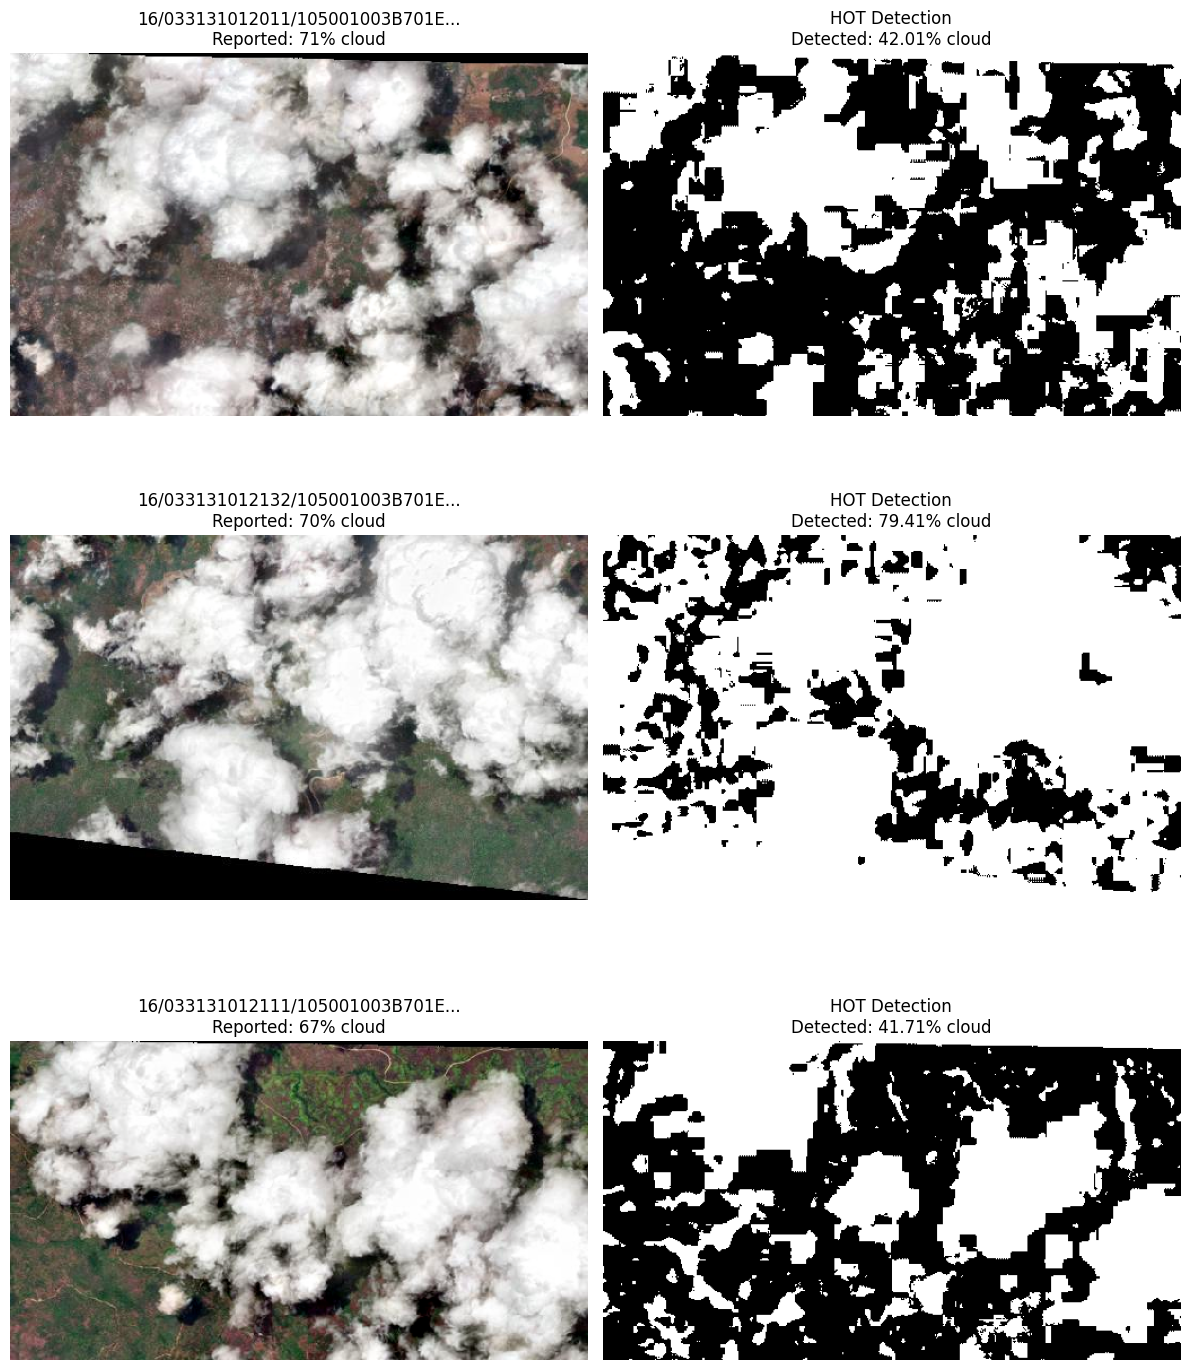

In [68]:
fig, axes = plt.subplots(len(results), 2, figsize=(12, 5*len(results)))
if len(results) == 1:
    axes = axes.reshape(1, -1)

for idx, result in enumerate(results):
    # Original RGB
    axes[idx, 0].imshow(result['rgb'])
    axes[idx, 0].set_title(f"{result['scene_id'][:30]}...\nReported: {result['reported_cloud']:.0f}% cloud")
    axes[idx, 0].axis('off')

    # HOT mask
    axes[idx, 1].imshow(result['mask'], cmap='gray')
    axes[idx, 1].set_title(f"HOT Detection\nDetected: {result['detected_cloud']:.2f}% cloud")
    axes[idx, 1].axis('off')

plt.tight_layout()
plt.show()

## 7. Summary

In [69]:
print("Tuned HOT Detection Results - Belize v1 (Threshold: -0.02)")
print("=" * 75)

for idx, result in enumerate(results):
    reported = result['reported_cloud']
    detected_percent = result['detected_cloud']

    print(f"\nScene: {result['scene_id']}")
    print(f"  Reported Metadata Cloud Cover: {reported:.0f}%")
    print(f"  Tuned HOT Detected Cover:      {detected_percent:.2f}%")
    print(f"  Difference from Metadata:      {abs(reported - detected_percent):.2f}%")

Tuned HOT Detection Results - Belize v1 (Threshold: -0.02)

Scene: 16/033131012011/105001003B701E00
  Reported Metadata Cloud Cover: 71%
  Tuned HOT Detected Cover:      42.01%
  Difference from Metadata:      28.99%

Scene: 16/033131012132/105001003B701E00
  Reported Metadata Cloud Cover: 70%
  Tuned HOT Detected Cover:      79.41%
  Difference from Metadata:      9.41%

Scene: 16/033131012111/105001003B701E00
  Reported Metadata Cloud Cover: 67%
  Tuned HOT Detected Cover:      41.71%
  Difference from Metadata:      25.29%


In [70]:
# Evaluate our tuned HOT predictions against a bright-pixel reference threshold mask
print("Evaluating HOT Predictions against Bright-Pixel Reference Masks:\n" + "="*60)

for idx, result in enumerate(results):
    rgb = result['rgb']
    pred_mask = result['mask']

    # Generate a simple bright-pixel reference (pixels where RGB channels average > 0.6)
    ref_mask = (np.mean(rgb, axis=2) > 0.6).astype(np.uint8)

    # Define a valid pixel mask (all pixels are valid for these resampled images)
    valid_mask = np.ones_like(ref_mask, dtype=np.uint8)

    # Evaluate
    metrics = evaluate(pred_mask, ref_mask, valid_mask)

    print(f"\nScene: {result['scene_id']}")
    print(f"  Precision: {metrics['precision']:.4f}")
    print(f"  Recall:    {metrics['recall']:.4f}")
    print(f"  F1-Score:  {metrics['f1']:.4f}")

Evaluating HOT Predictions against Bright-Pixel Reference Masks:

Scene: 16/033131012011/105001003B701E00
  Precision: 0.6497
  Recall:    0.5569
  F1-Score:  0.5997

Scene: 16/033131012132/105001003B701E00
  Precision: 0.5505
  Recall:    0.8943
  F1-Score:  0.6815

Scene: 16/033131012111/105001003B701E00
  Precision: 0.7627
  Recall:    0.6458
  F1-Score:  0.6994


## 8. Notes & Next Steps

**v1 Status:**
- ✅ **Normalization Bug Fixed**: Addressed double-scaling within `detect_hot` to work natively on `[0, 1]` stretched bands.
- ✅ **Calibrated Threshold**: Tuned HOT threshold to **`-0.02`** specifically for the Belize patch scenes to capture thick white clouds.

**Next steps when shared team utilities are ready:**
- Transition from low-resolution overviews (512x512) to full-resolution processing tiles.
- Plug this calibrated `detect_hot(image, threshold=-0.02)` into the shared tiling helpers and batch runner.
- Inspect boundary performance and edge cases using GIS mapping tools.
```